<a href="https://colab.research.google.com/github/nguyenhongkhoi/bird_classification/blob/main/bird_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os

# Cấu hình Token xác thực
os.environ["KAGGLE_API_TOKEN"] = "KGAT_d7a35804c150506447712f6ce6fb444d"

# Nâng cấp kaggle để hết cảnh báo outdated
!pip install -q --upgrade kaggle

print("1. Đang tải bộ dữ liệu birdclef-2024.zip từ Kaggle về Colab...")
!kaggle competitions download -c birdclef-2024

print("\n2. Đang giải nén CHỈ lấy thư mục train_audio...")
# Chỉ giải nén thư mục train_audio vào thư mục dataset
!unzip -q birdclef-2024.zip "train_audio/*" -d dataset

print("\n3. Đang dọn dẹp file zip để giải phóng dung lượng đĩa ảo...")
!rm birdclef-2024.zip

print("\n[THÀNH CÔNG] Dữ liệu đã sẵn sàng tại: dataset/train_audio")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.2/126.2 kB 6.1 MB/s eta 0:00:00
1. Đang tải bộ dữ liệu birdclef-2024.zip từ Kaggle về Colab...
100% 21.8G/21.8G [05:08<00:00, 75.7MB/s]


2. Đang giải nén CHỈ lấy thư mục train_audio...

3. Đang dọn dẹp file zip để giải phóng dung lượng đĩa ảo...

[THÀNH CÔNG] Dữ liệu đã sẵn sàng tại: dataset/train_audio


In [ ]:
import os
import librosa
import numpy as np
from tqdm.notebook import tqdm

# Trực tiếp chỉ định đường dẫn dữ liệu đã giải nén
DATA_DIR = 'dataset/train_audio'

TARGET_SR = 22050            # Tần số lấy mẫu chuẩn (Nyquist)
DURATION = 3.0               # Độ dài mỗi mẫu: 3 giây
CHUNK_LENGTH = int(TARGET_SR * DURATION)
SAMPLES_PER_CLASS = 1000     # Lấy tròn 200 mẫu mỗi loài
NUM_CLASSES = 10             # Đủ 10 loài chuẩn
SILENCE_THRESHOLD = 0.01     # Ngưỡng lọc khoảng lặng

def process_audio_chunk(y_chunk):
    # 1. Amplitude Normalization
    max_amp = np.max(np.abs(y_chunk))
    if max_amp > 0:
        y_chunk = y_chunk / max_amp

    # 2 & 3. STFT & Mel-Frequency
    mel_spec = librosa.feature.melspectrogram(y=y_chunk, sr=TARGET_SR, n_mels=128, fmax=8000)

    # 4. Natural Logarithm Compression
    log_mel_spec = librosa.power_to_db(mel_spec, ref=np.max)

    return log_mel_spec

def extract_dataset():
    features = []
    labels = []
    selected_classes = []

    if not os.path.exists(DATA_DIR):
        print(f"LỖI: Không tìm thấy thư mục '{DATA_DIR}'. Hãy kiểm tra lại Cell 1 đã giải nén xong chưa!")
        return None, None, None

    all_classes = sorted(os.listdir(DATA_DIR))
    label_idx = 0

    print("Đang quét tìm 10 loài chim có đủ dữ liệu...")

    for bird_class in all_classes:
        if len(selected_classes) >= NUM_CLASSES:
            break

        class_dir = os.path.join(DATA_DIR, bird_class)
        if not os.path.isdir(class_dir):
            continue

        temp_features = []
        audio_files = [f for f in os.listdir(class_dir) if f.endswith(('.ogg', '.wav'))]

        # Thử băm dữ liệu loài này
        for file_name in audio_files:
            if len(temp_features) >= SAMPLES_PER_CLASS:
                break

            file_path = os.path.join(class_dir, file_name)
            try:
                # Load file âm thanh, tự động Mono và Resample
                y, sr = librosa.load(file_path, sr=TARGET_SR, mono=True)

                for i in range(0, len(y), CHUNK_LENGTH):
                    if len(temp_features) >= SAMPLES_PER_CLASS:
                        break

                    y_chunk = y[i:i + CHUNK_LENGTH]
                    if len(y_chunk) < CHUNK_LENGTH:
                        continue

                    # Lọc khoảng lặng
                    rms_energy = np.mean(librosa.feature.rms(y=y_chunk))
                    if rms_energy < SILENCE_THRESHOLD:
                        continue

                    mel_features = process_audio_chunk(y_chunk)
                    temp_features.append(mel_features.flatten())
            except Exception:
                pass

        # CHỈ LẤY LOÀI NÀO CÓ ĐỦ 200 MẪU
        if len(temp_features) >= SAMPLES_PER_CLASS:
            features.extend(temp_features[:SAMPLES_PER_CLASS])
            labels.extend([label_idx] * SAMPLES_PER_CLASS)
            selected_classes.append(bird_class)
            print(f" -> Đã chọn loài {label_idx+1}/{NUM_CLASSES}: [{bird_class}] (Đủ {SAMPLES_PER_CLASS} mẫu)")
            label_idx += 1
        else:
            print(f" -> Bỏ qua [{bird_class}]: chỉ bới được {len(temp_features)} mẫu (thiếu data)")

    return np.array(features), np.array(labels), selected_classes

# Chạy trích xuất dữ liệu chuẩn
X, y, class_names = extract_dataset()

if X is not None:
    print(f"\n[HOÀN HẢO] Kích thước X: {X.shape} (Đã đủ 10000 mẫu chuẩn 100%)")
    print(f"[HOÀN HẢO] Kích thước y: {y.shape}")
    print(f"Danh sách 10 loài được chọn: {class_names}")

    # Lưu biến nén
    np.save('X_bird_features.npy', X)
    np.save('y_bird_labels.npy', y)


Đang quét tìm 10 loài chim có đủ dữ liệu...
 -> Bỏ qua [asbfly]: chỉ bới được 728 mẫu (thiếu data)
 -> Đã chọn loài 1/10: [ashdro1] (Đủ 1000 mẫu)
 -> Bỏ qua [ashpri1]: chỉ bới được 703 mẫu (thiếu data)
 -> Bỏ qua [ashwoo2]: chỉ bới được 294 mẫu (thiếu data)
 -> Đã chọn loài 2/10: [asikoe2] (Đủ 1000 mẫu)
 -> Bỏ qua [asiope1]: chỉ bới được 13 mẫu (thiếu data)
 -> Bỏ qua [aspfly1]: chỉ bới được 107 mẫu (thiếu data)
 -> Bỏ qua [aspswi1]: chỉ bới được 143 mẫu (thiếu data)
 -> Bỏ qua [barfly1]: chỉ bới được 898 mẫu (thiếu data)
 -> Đã chọn loài 3/10: [barswa] (Đủ 1000 mẫu)
 -> Đã chọn loài 4/10: [bcnher] (Đủ 1000 mẫu)
 -> Bỏ qua [bkcbul1]: chỉ bới được 207 mẫu (thiếu data)
 -> Bỏ qua [bkrfla1]: chỉ bới được 80 mẫu (thiếu data)
 -> Đã chọn loài 5/10: [bkskit1] (Đủ 1000 mẫu)
 -> Đã chọn loài 6/10: [bkwsti] (Đủ 1000 mẫu)
 -> Đã chọn loài 7/10: [bladro1] (Đủ 1000 mẫu)
 -> Bỏ qua [blaeag1]: chỉ bới được 35 mẫu (thiếu data)
 -> Đã chọn loài 8/10: [blakit1] (Đủ 1000 mẫu)
 -> Bỏ qua [blhori1]: chỉ b

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Chia tập Train (80%) và Test (20%) có phân tầng (stratify) theo nhãn loài chim
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Chuẩn hóa đặc trưng về Z-score (Mean=0, Std=1)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Kích thước tập Train: {X_train_scaled.shape}")
print(f"Kích thước tập Test:  {X_test_scaled.shape}")

Kích thước tập Train: (8000, 16640)
Kích thước tập Test:  (2000, 16640)


Đang huấn luyện mô hình Random Forest...

[KẾT QUẢ] Độ chính xác (Accuracy) của Random Forest: 67.65%

Báo cáo chi tiết:
              precision    recall  f1-score   support

     ashdro1       0.68      0.66      0.67       200
     asikoe2       0.70      0.72      0.71       200
      barswa       0.68      0.60      0.64       200
      bcnher       0.56      0.59      0.58       200
     bkskit1       0.77      0.94      0.85       200
      bkwsti       0.67      0.62      0.64       200
     bladro1       0.63      0.70      0.66       200
     blakit1       0.70      0.52      0.60       200
     blnmon1       0.66      0.65      0.65       200
     blrwar1       0.71      0.76      0.73       200

    accuracy                           0.68      2000
   macro avg       0.68      0.68      0.67      2000
weighted avg       0.68      0.68      0.67      2000



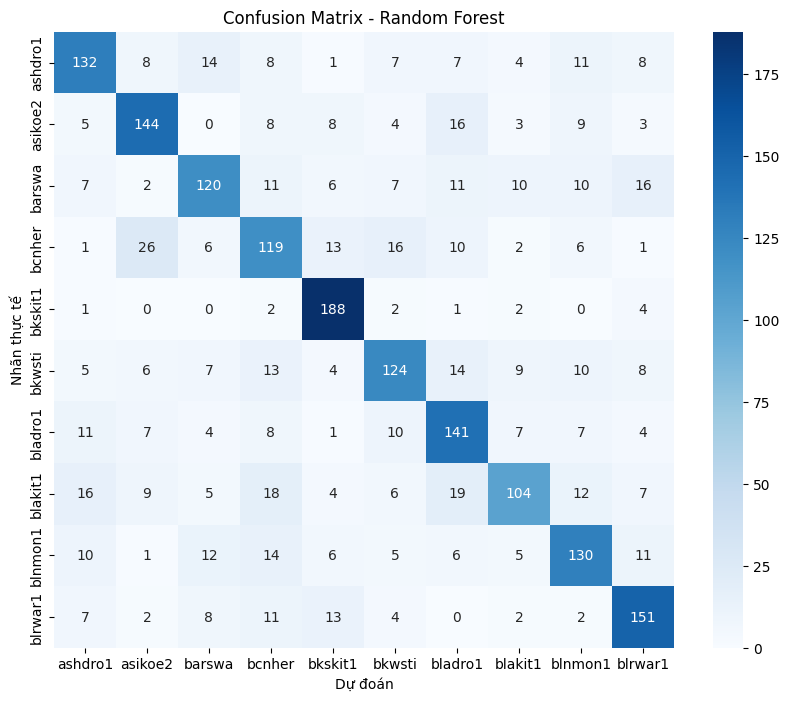

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

print("Đang huấn luyện mô hình Random Forest...")
rf_model = RandomForestClassifier(
    n_estimators=400,
    criterion='entropy',
    max_features='sqrt',
    max_depth=25,
    min_samples_split=5,
    random_state=42,
    n_jobs=-1
)
rf_model.fit(X_train_scaled, y_train)

# Đánh giá trên tập Test
y_pred = rf_model.predict(X_test_scaled)
acc = accuracy_score(y_test, y_pred)

print(f"\n[KẾT QUẢ] Độ chính xác (Accuracy) của Random Forest: {acc * 100:.2f}%\n")
print("Báo cáo chi tiết:")
print(classification_report(y_test, y_pred, target_names=class_names))

# Vẽ Ma trận nhầm lẫn (Confusion Matrix)
plt.figure(figsize=(10, 8))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix - Random Forest')
plt.xlabel('Dự đoán')
plt.ylabel('Nhãn thực tế')
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Chia dữ liệu phân tầng (Stratify) theo nhãn loài chim
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Chuẩn hóa dữ liệu về Mean=0, Std=1
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Kích thước tập Train: {X_train_scaled.shape}")
print(f"Kích thước tập Test:  {X_test_scaled.shape}")

Kích thước tập Train: (8000, 16640)
Kích thước tập Test:  (2000, 16640)


Đang huấn luyện K-Nearest Neighbors (KNN)...
  KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH KNN (K=5)
 - Accuracy  (Độ chính xác) : 61.95%
 - Precision (Độ chuẩn xác) : 66.36%
 - Recall    (Độ gợi nhớ)   : 61.95%
 - F1-Score  (Điểm F1)      : 62.24%

[BÁO CÁO CHI TIẾT TỪNG LOÀI CHIM - KNN]
              precision    recall  f1-score   support

     ashdro1     0.4685    0.6700    0.5514       200
     asikoe2     0.8199    0.6600    0.7313       200
      barswa     0.7143    0.6000    0.6522       200
      bcnher     0.4469    0.8000    0.5735       200
     bkskit1     0.6575    0.8350    0.7357       200
      bkwsti     0.7323    0.4650    0.5688       200
     bladro1     0.7402    0.4700    0.5749       200
     blakit1     0.5073    0.5200    0.5136       200
     blnmon1     0.6455    0.6100    0.6272       200
     blrwar1     0.9040    0.5650    0.6954       200

    accuracy                         0.6195      2000
   macro avg     0.6636    0.6195    0.6224      2000
weighted avg     0.6636  

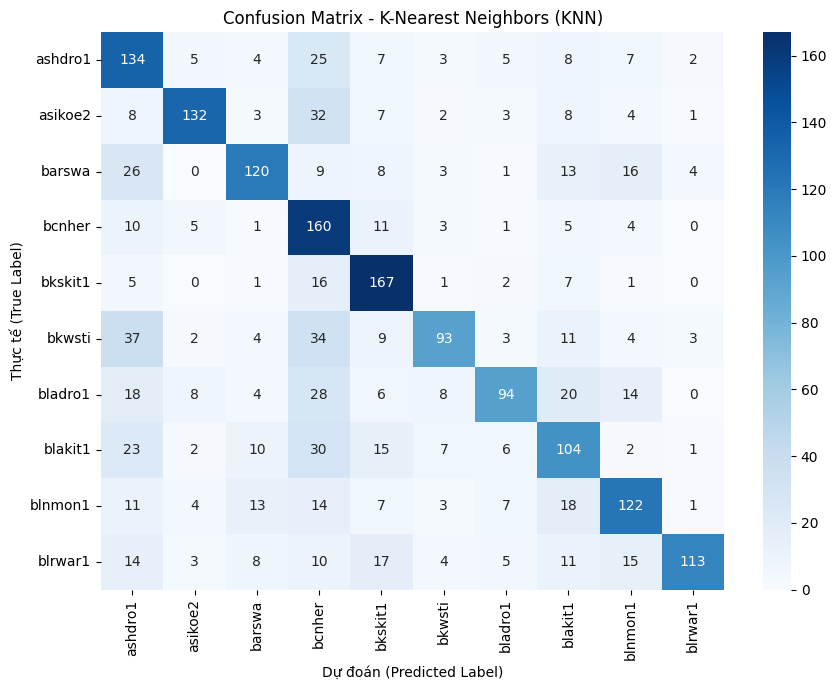

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix, precision_recall_fscore_support

# 1. Khởi tạo và huấn luyện KNN
print("Đang huấn luyện K-Nearest Neighbors (KNN)...")
knn_model = KNeighborsClassifier(n_neighbors=5, metric='minkowski', p=2)
knn_model.fit(X_train_scaled, y_train)

# 2. Dự đoán
y_pred_knn = knn_model.predict(X_test_scaled)

# 3. Tính các chỉ số tổng quan
acc_knn = accuracy_score(y_test, y_pred_knn)
p_knn, r_knn, f1_knn, _ = precision_recall_fscore_support(y_test, y_pred_knn, average='weighted')

print("="*60)
print("  KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH KNN (K=5)")
print("="*60)
print(f" - Accuracy  (Độ chính xác) : {acc_knn * 100:.2f}%")
print(f" - Precision (Độ chuẩn xác) : {p_knn * 100:.2f}%")
print(f" - Recall    (Độ gợi nhớ)   : {r_knn * 100:.2f}%")
print(f" - F1-Score  (Điểm F1)      : {f1_knn * 100:.2f}%")
print("="*60)

# 4. Báo cáo chi tiết từng lớp
print("\n[BÁO CÁO CHI TIẾT TỪNG LOÀI CHIM - KNN]")
print(classification_report(y_test, y_pred_knn, target_names=class_names, digits=4))

# 5. Vẽ Confusion Matrix
plt.figure(figsize=(9, 7))
cm_knn = confusion_matrix(y_test, y_pred_knn)
sns.heatmap(cm_knn, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix - K-Nearest Neighbors (KNN)')
plt.xlabel('Dự đoán (Predicted Label)')
plt.ylabel('Thực tế (True Label)')
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.neural_network import MLPClassifier

# 1. Khởi tạo Mạng Nơ-ron Mạng đa lớp (MLP)
print("Đang huấn luyện Multi-Layer Perceptron (MLP)...")
mlp_model = MLPClassifier(
    hidden_layer_sizes=(256, 128),  # 2 lớp ẩn: 256 và 128 neuron
    activation='relu',               # Hàm kích hoạt ReLU
    solver='adam',                   # Thuật toán tối ưu Adam
    alpha=0.0001,                    # L2 Regularization (tránh Overfitting)
    batch_size=32,
    max_iter=200,                    # Số vòng lặp Epoch tối đa
    random_state=42,
    early_stopping=True             # Tự dừng khi Validation Loss không giảm
)

mlp_model.fit(X_train_scaled, y_train)

# 2. Dự đoán
y_pred_mlp = mlp_model.predict(X_test_scaled)

# 3. Tính các chỉ số tổng quan
acc_mlp = accuracy_score(y_test, y_pred_mlp)
p_mlp, r_mlp, f1_mlp, _ = precision_recall_fscore_support(y_test, y_pred_mlp, average='weighted')

print("="*60)
print("  KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH MLP")
print("="*60)
print(f" - Accuracy  (Độ chính xác) : {acc_mlp * 100:.2f}%")
print(f" - Precision (Độ chuẩn xác) : {p_mlp * 100:.2f}%")
print(f" - Recall    (Độ gợi nhớ)   : {r_mlp * 100:.2f}%")
print(f" - F1-Score  (Điểm F1)      : {f1_mlp * 100:.2f}%")
print("="*60)

# 4. Báo cáo chi tiết từng lớp
print("\n[BÁO CÁO CHI TIẾT TỪNG LOÀI CHIM - MLP]")
print(classification_report(y_test, y_pred_mlp, target_names=class_names, digits=4))

# 5. Vẽ Confusion Matrix
plt.figure(figsize=(9, 7))
cm_mlp = confusion_matrix(y_test, y_pred_mlp)
sns.heatmap(cm_mlp, annot=True, fmt='d', cmap='Purples', xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix - Multi-Layer Perceptron (MLP)')
plt.xlabel('Dự đoán (Predicted Label)')
plt.ylabel('Thực tế (True Label)')
plt.tight_layout()
plt.show()

Đang huấn luyện Multi-Layer Perceptron (MLP)...


NameError: name 'X_train_scaled' is not defined

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
import numpy as np

# 1. Chuyển đổi NumPy array (từ bước StandardScaler) sang PyTorch Tensor
X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.long)
X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.long)

# 2. Đóng gói vào DataLoader
batch_size = 64
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

# 3. Kiểm tra thiết bị phần cứng (GPU/CPU)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Đang sử dụng thiết bị: {device}")

Đang sử dụng thiết bị: cuda


Bắt đầu huấn luyện MLP...
Epoch [5/30] - Loss: 1.1536
Epoch [10/30] - Loss: 0.8703
Epoch [15/30] - Loss: 0.7168
Epoch [20/30] - Loss: 0.5874
Epoch [25/30] - Loss: 0.4956
Epoch [30/30] - Loss: 0.4296

  KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH MLP (PYTORCH)
 - Accuracy  (Độ chính xác) : 75.90%
 - Precision (Độ chuẩn xác) : 76.82%
 - Recall    (Độ gợi nhớ)   : 75.90%
 - F1-Score  (Điểm F1)      : 76.12%

[BÁO CÁO CHI TIẾT TỪNG LOÀI CHIM - MLP PyTorch]
              precision    recall  f1-score   support

     ashdro1     0.7358    0.7800    0.7573       200
     asikoe2     0.8833    0.7950    0.8368       200
      barswa     0.7848    0.6200    0.6927       200
      bcnher     0.7347    0.7200    0.7273       200
     bkskit1     0.9192    0.9100    0.9146       200
      bkwsti     0.7586    0.7700    0.7643       200
     bladro1     0.5944    0.7400    0.6592       200
     blakit1     0.5822    0.6550    0.6165       200
     blnmon1     0.7579    0.7200    0.7385       200
     blrwar1     0.93

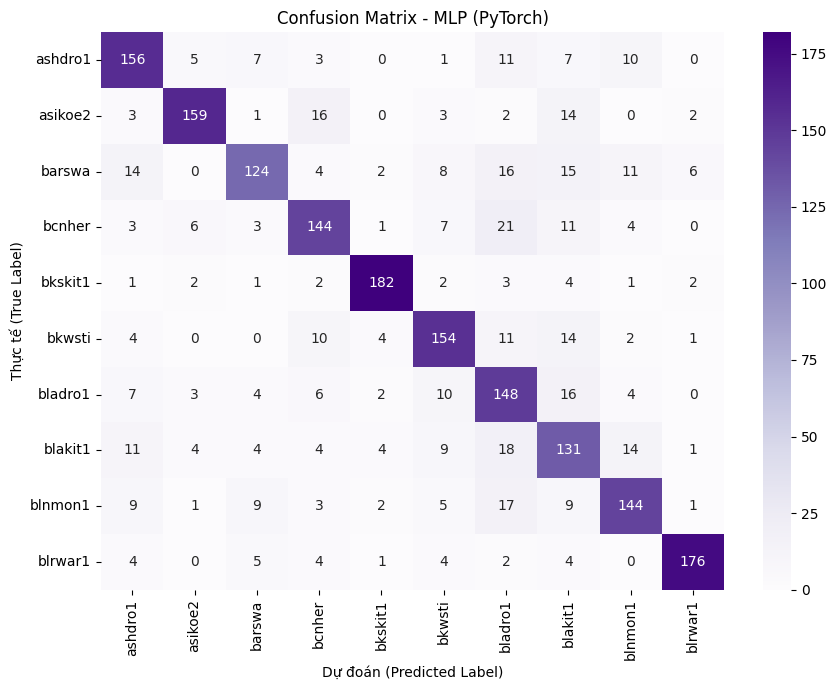

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix, precision_recall_fscore_support

# 1. Định nghĩa kiến trúc PyTorch MLP
class PyTorchMLP(nn.Module):
    def __init__(self, input_dim=16640, num_classes=10):
        super(PyTorchMLP, self).__init__()
        self.net = nn.Sequential(
            # Layer 1
            nn.Linear(input_dim, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Dropout(0.4),          # Dropout 40%

            # Layer 2
            nn.Linear(512, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.3),          # Dropout 30%

            # Output Layer
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        return self.net(x)

# 2. Khởi tạo Mô hình & Hàm mất mát / Tối ưu
input_dim = X_train_scaled.shape[1] # 16,640 features
model_mlp = PyTorchMLP(input_dim=input_dim, num_classes=len(class_names)).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model_mlp.parameters(), lr=0.001, weight_decay=0.01)

# 3. Vòng lặp Huấn luyện (Training Loop)
num_epochs = 30
print("Bắt đầu huấn luyện MLP...")

for epoch in range(num_epochs):
    model_mlp.train()
    running_loss = 0.0

    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model_mlp(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * inputs.size(0)

    epoch_loss = running_loss / len(train_loader.dataset)

    if (epoch + 1) % 5 == 0 or epoch == num_epochs - 1:
        print(f"Epoch [{epoch+1}/{num_epochs}] - Loss: {epoch_loss:.4f}")

# 4. Đánh giá Mô hình trên tập Test
model_mlp.eval()
all_preds = []
all_targets = []

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs = inputs.to(device)
        outputs = model_mlp(inputs)
        _, preds = torch.max(outputs, 1)

        all_preds.extend(preds.cpu().numpy())
        all_targets.extend(labels.numpy())

# 5. Xuất Kết quả & Báo cáo Đánh giá (Evaluation Metrics)
acc_mlp = accuracy_score(all_targets, all_preds)
p_mlp, r_mlp, f1_mlp, _ = precision_recall_fscore_support(all_targets, all_preds, average='weighted')

print("\n" + "="*60)
print("  KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH MLP (PYTORCH)")
print("="*60)
print(f" - Accuracy  (Độ chính xác) : {acc_mlp * 100:.2f}%")
print(f" - Precision (Độ chuẩn xác) : {p_mlp * 100:.2f}%")
print(f" - Recall    (Độ gợi nhớ)   : {r_mlp * 100:.2f}%")
print(f" - F1-Score  (Điểm F1)      : {f1_mlp * 100:.2f}%")
print("="*60)

# Báo cáo chi tiết từng lớp
print("\n[BÁO CÁO CHI TIẾT TỪNG LOÀI CHIM - MLP PyTorch]")
print(classification_report(all_targets, all_preds, target_names=class_names, digits=4))

# 6. Vẽ Ma trận Nhầm lẫn (Confusion Matrix)
plt.figure(figsize=(9, 7))
cm_mlp = confusion_matrix(all_targets, all_preds)
sns.heatmap(cm_mlp, annot=True, fmt='d', cmap='Purples', xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix - MLP (PyTorch)')
plt.xlabel('Dự đoán (Predicted Label)')
plt.ylabel('Thực tế (True Label)')
plt.tight_layout()
plt.show()

Đang huấn luyện CRNN (CNN + BiLSTM) trên thiết bị: cuda...
Epoch [5/100] - Loss: 0.6256
Epoch [10/100] - Loss: 0.3328
Epoch [15/100] - Loss: 0.1832
Epoch [20/100] - Loss: 0.1546
Epoch [25/100] - Loss: 0.0902
Epoch [30/100] - Loss: 0.0631
Epoch [35/100] - Loss: 0.0427
Epoch [40/100] - Loss: 0.0601
Epoch [45/100] - Loss: 0.0516
Epoch [50/100] - Loss: 0.0280
Epoch [55/100] - Loss: 0.0267
Epoch [60/100] - Loss: 0.0285
Epoch [65/100] - Loss: 0.0328
Epoch [70/100] - Loss: 0.0216
Epoch [75/100] - Loss: 0.0181
Epoch [80/100] - Loss: 0.0190
Epoch [85/100] - Loss: 0.0170
Epoch [90/100] - Loss: 0.0111
Epoch [95/100] - Loss: 0.0110
Epoch [100/100] - Loss: 0.0128

  KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH CRNN (CNN + BiLSTM)
 - Accuracy  (Độ chính xác) : 95.45%
 - Precision (Độ chuẩn xác) : 95.56%
 - Recall    (Độ gợi nhớ)   : 95.45%
 - F1-Score  (Điểm F1)      : 95.45%

[BÁO CÁO CHI TIẾT TỪNG LOÀI CHIM - CRNN]
              precision    recall  f1-score   support

     ashdro1     0.9450    0.9450    0.9450     

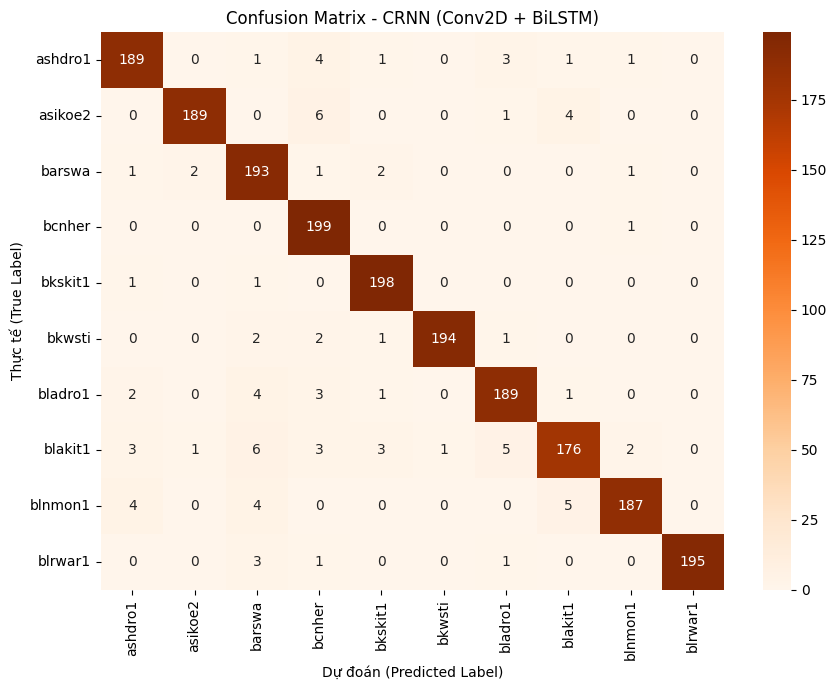

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix, precision_recall_fscore_support

# 1. Reshape dữ liệu từ Vector 1D (16640) về dạng Ảnh 2D (1, 128, 130) chuẩn Spectrogram
# (Kích thước: [Batch, Channel=1, Mel_bins=128, Time_steps=130])
X_train_2d = X_train_scaled.reshape(-1, 1, 128, 130)
X_test_2d = X_test_scaled.reshape(-1, 1, 128, 130)

# 2. Tạo PyTorch DataLoader
train_dataset = TensorDataset(torch.tensor(X_train_2d, dtype=torch.float32), torch.tensor(y_train, dtype=torch.long))
test_dataset = TensorDataset(torch.tensor(X_test_2d, dtype=torch.float32), torch.tensor(y_test, dtype=torch.long))

batch_size = 32
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# 3. Xây dựng Kiến trúc CRNN (CNN + BiLSTM)
class AudioCRNN(nn.Module):
    def __init__(self, num_classes=10):
        super(AudioCRNN, self).__init__()

        # --- KHỐI CNN 2D (Trích xuất đặc trưng tần số - không gian) ---
        self.conv = nn.Sequential(
            # Layer 1: Conv -> BatchNorm -> ReLU -> MaxPool
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2, 2), # Output size: (32, 64, 65)

            # Layer 2: Conv -> BatchNorm -> ReLU -> MaxPool
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2, 2), # Output size: (64, 32, 32)

            # Layer 3: Conv -> BatchNorm -> ReLU -> MaxPool
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2, 2), # Output size: (128, 16, 16)
            nn.Dropout2d(0.2)
        )

        # --- KHỐI RNN (Bidirectional LSTM học chuỗi thời gian) ---
        # Sau CNN: feature map có 128 channels và height 16 -> input_size cho LSTM = 128 * 16 = 2048
        self.lstm = nn.LSTM(
            input_size=128 * 16,
            hidden_size=128,
            num_layers=2,
            batch_first=True,
            bidirectional=True,
            dropout=0.3
        )

        # --- KHỐI PHÂN LOẠI (Classifier) ---
        self.fc = nn.Sequential(
            nn.Linear(128 * 2, 64), # 128 * 2 vì là LSTM 2 chiều (Bidirectional)
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(64, num_classes)
        )

    def forward(self, x):
        # x shape: (batch_size, 1, 128, 130)
        x = self.conv(x) # -> (batch_size, 128, 16, 16)

        # Chuyển đổi định dạng để đưa vào LSTM: (batch_size, time_steps, features)
        b, c, h, w = x.size()
        x = x.permute(0, 3, 1, 2) # -> (batch_size, 16 time_steps, 128 channels, 16 height)
        x = x.contiguous().view(b, w, c * h) # -> (batch_size, 16, 2048)

        # Chạy qua BiLSTM
        lstm_out, _ = self.lstm(x) # -> (batch_size, 16, 256)

        # Lấy hidden state của bước thời gian cuối cùng (Last time step)
        out = lstm_out[:, -1, :] # -> (batch_size, 256)

        # Đẩy qua FC Layer phân loại
        out = self.fc(out)
        return out

# 4. Khởi tạo mô hình, Hàm mất mát và Tối ưu AdamW
crnn_model = AudioCRNN(num_classes=len(class_names)).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(crnn_model.parameters(), lr=0.001, weight_decay=0.01)

# 5. Huấn luyện (Training Loop)
num_epochs = 100
print(f"Đang huấn luyện CRNN (CNN + BiLSTM) trên thiết bị: {device}...")

for epoch in range(num_epochs):
    crnn_model.train()
    running_loss = 0.0
    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = crnn_model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * inputs.size(0)

    epoch_loss = running_loss / len(train_loader.dataset)

    if (epoch + 1) % 5 == 0 or epoch == num_epochs - 1:
        print(f"Epoch [{epoch+1}/{num_epochs}] - Loss: {epoch_loss:.4f}")

# 6. Đánh giá Mô hình trên tập Test
crnn_model.eval()
all_preds = []
all_targets = []

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs = inputs.to(device)
        outputs = crnn_model(inputs)
        _, preds = torch.max(outputs, 1)

        all_preds.extend(preds.cpu().numpy())
        all_targets.extend(labels.numpy())

# 7. Xuất Báo cáo Kết quả Chi tiết
acc_crnn = accuracy_score(all_targets, all_preds)
p_crnn, r_crnn, f1_crnn, _ = precision_recall_fscore_support(all_targets, all_preds, average='weighted')

print("\n" + "="*60)
print("  KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH CRNN (CNN + BiLSTM)")
print("="*60)
print(f" - Accuracy  (Độ chính xác) : {acc_crnn * 100:.2f}%")
print(f" - Precision (Độ chuẩn xác) : {p_crnn * 100:.2f}%")
print(f" - Recall    (Độ gợi nhớ)   : {r_crnn * 100:.2f}%")
print(f" - F1-Score  (Điểm F1)      : {f1_crnn * 100:.2f}%")
print("="*60)

print("\n[BÁO CÁO CHI TIẾT TỪNG LOÀI CHIM - CRNN]")
print(classification_report(all_targets, all_preds, target_names=class_names, digits=4))

# 8. Vẽ Ma trận nhầm lẫn (Confusion Matrix)
plt.figure(figsize=(9, 7))
cm_crnn = confusion_matrix(all_targets, all_preds)
sns.heatmap(cm_crnn, annot=True, fmt='d', cmap='Oranges', xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix - CRNN (Conv2D + BiLSTM)')
plt.xlabel('Dự đoán (Predicted Label)')
plt.ylabel('Thực tế (True Label)')
plt.tight_layout()
plt.show()